# Task 1 — Summary statistics hide radically different shapes

Completed Week 1 assignment. Every chart is followed by its design justification and interpretation.

**Run:** Python 3 with `pandas`, `numpy`, `matplotlib`, `seaborn`, and `IPython`. Use **Restart Kernel and Run All**. The original CSV is embedded, so no network or extra data files are needed.

**Data source:** [datasaurus.csv](https://raw.githubusercontent.com/rfordatascience/tidytuesday/master/data/2020/2020-10-13/datasaurus.csv), downloaded 30 September 2026 using the assignment script's source URL. These are historical teaching datasets, not current-world estimates.

**Chart policy:** finding-led titles, no dual y-axes, zero-based bars, meaningful colour and selective labels. The deliberately messy Task 2 chart is the required counterexample.

In [1]:
import base64, zlib, io
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
import seaborn as sns
from IPython.display import display
sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams.update({"figure.dpi": 115, "axes.spines.top": False,
                     "axes.spines.right": False, "axes.titleweight": "bold"})
BLUE, ORANGE, GREEN = "#0072B2", "#D55E00", "#009E73"
def finish(fig, note):
    fig.text(0.01, 0.012, note, fontsize=9, color="#555555")
    fig.tight_layout(rect=(0, 0.065, 1, 0.96))
    plt.show()

# Compressed CSV snapshot from the source linked above.
# Replace df with pd.read_csv("data/datasaurus.csv") to use your local assignment file.
CSV_B64 = (
    '...'
    '/z9kjN92'
)
df = pd.read_csv(io.BytesIO(zlib.decompress(base64.b64decode(CSV_B64))))
assert len(df) == 1846
print("Shape:", df.shape)
display(df.head())
display(df.isna().sum().rename("missing rows").to_frame())

Shape: (1846, 3)


,dataset,x,y
0,dino,55.3846,97.1795
1,dino,51.5385,96.0256
2,dino,46.1538,94.4872
3,dino,42.8205,91.4103
4,dino,40.7692,88.3333


,missing rows
dataset,0
x,0
y,0


## 1. One summary table
Sample standard deviations use `ddof=1`; correlation is Pearson’s r.

In [2]:
assert df.isna().sum().sum() == 0
assert df.groupby('dataset').size().eq(142).all()
summary = df.groupby('dataset').agg(n=('x', 'size'), mean_x=('x', 'mean'),
    mean_y=('y', 'mean'), sd_x=('x', 'std'), sd_y=('y', 'std'))
summary['correlation'] = pd.Series({name: g.x.corr(g.y) for name, g in df.groupby('dataset')})
display(summary.round(4))
print('Range across datasets:')
display((summary.drop(columns='n').max()-summary.drop(columns='n').min()).rename('range').to_frame())

Range across datasets:


,n,mean_x,mean_y,sd_x,sd_y,correlation
dataset,,,,,,
away,142,54.2661,47.8347,16.7698,26.9397,-0.0641
bullseye,142,54.2687,47.8308,16.7692,26.9357,-0.0686
circle,142,54.2673,47.8377,16.7600,26.9300,-0.0683
dino,142,54.2633,47.8323,16.7651,26.9354,-0.0645
dots,142,54.2603,47.8398,16.7677,26.9302,-0.0603
h_lines,142,54.2614,47.8303,16.7659,26.9399,-0.0617
high_lines,142,54.2688,47.8355,16.7667,26.9400,-0.0685
slant_down,142,54.2678,47.8359,16.7668,26.9361,-0.0690
slant_up,142,54.2659,47.8315,16.7689,26.9386,-0.0686


,range
mean_x,0.009777
mean_y,0.009577
sd_x,0.009987
sd_y,0.009996
correlation,0.009104


## 2. What I would conclude from the table alone
The 13 groups appear very similar: mean x is about 54.3, mean y about 47.8, the sample standard deviations about 16.8 and 26.9, and the correlations about −0.06. I would describe similar location and spread, with little **linear** association. It would be tempting to conclude that the datasets are interchangeable, but these statistics cannot establish their shapes or rule out nonlinear relationships.

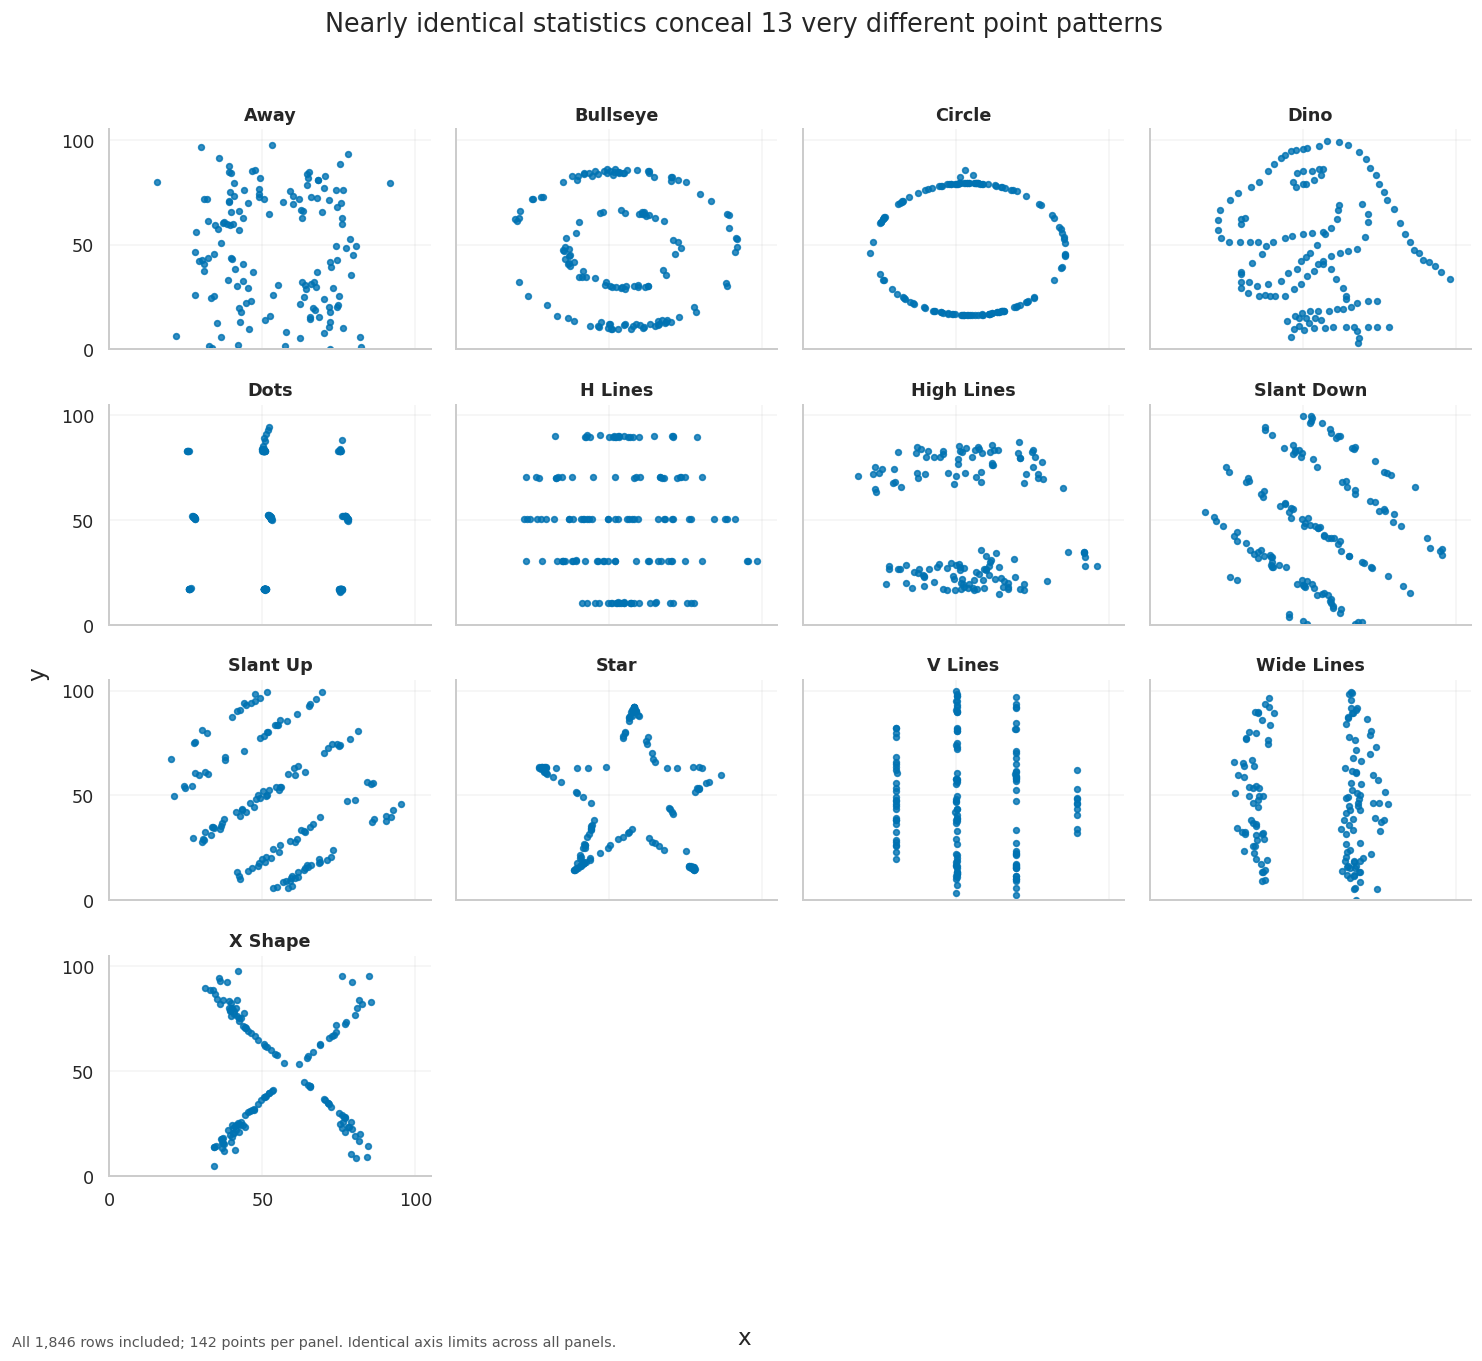

In [3]:
names = sorted(df.dataset.unique())
fig, axes = plt.subplots(4, 4, figsize=(13, 12), sharex=True, sharey=True)
for ax, name in zip(axes.flat, names):
    g = df[df.dataset.eq(name)]
    ax.scatter(g.x, g.y, s=13, color=BLUE, alpha=.8)
    ax.set_title(name.replace('_', ' ').title(), fontsize=11)
    ax.set(xlim=(0, 105), ylim=(0, 105), xticks=[0, 50, 100], yticks=[0, 50, 100])
    ax.grid(alpha=.22)
for ax in axes.flat[len(names):]:
    ax.set_visible(False)
fig.suptitle('Nearly identical statistics conceal 13 very different point patterns', fontsize=16)
fig.supxlabel('x'); fig.supylabel('y')
finish(fig, 'All 1,846 rows included; 142 points per panel. Identical axis limits across all panels.')

**Why scatter plots:** Both variables are numeric; plotting each pair preserves geometry, clusters, outliers and nonlinear structure. Small multiples with identical scales let me compare all 13 fairly. Blue has no group meaning here; it is simply one consistent ink colour.

## 4. What the plots actually reveal
The points form a dinosaur, a star, circles, lines, a cross, separate clouds and other structured patterns. The near-zero correlations hide striking relationships because Pearson’s r measures linear association, not arbitrary shape. Equal means and standard deviations do not make distributions equal.

**Answer to the main question:** No. Having 13 groups of 142 points does not make these particular summaries sufficient. More observations may improve estimation under an appropriate sampling model, but they cannot recover information discarded by a mean, standard deviation or correlation. These deliberately constructed datasets demonstrate information loss, not a failure of the calculations. I would report statistics **and** plots.